# 298. Could linked word pairs reach ice-binding proteins of other lineages where k-mers could not?

**Verdict: KILL at stage 1. No search was run.** The setting chosen on four lineages (the
20 amino acids, 4-letter words, every pair, spacing // 3 in the key) reaches 4 of 55
ice-binding proteins from the held-out AFGP query, fewer than the best exact k-mer
(6 of 55), and 0 of 40 from the held-out fish type III query, the same as the best exact
k-mer. The rule needed 10 points more on both. Under the 1% random-share bar, no
hydrophobic-polar or threonine key reaches more than 1 ice-binding protein of another
lineage from any query. The matches that do exist are proteins that share an ancestor
(the bacterial query and five fungal proteins of UniProt's "Ice-binding protein family")
or alanine and threonine runs (AFGP against fish type I).

**The question.** [Notebook 295](295_convergence_search_ice_binding_proteins_swissprot.ipynb) section 9 ([PR 141](https://github.com/seanome/2024-kmerseek-analysis/pull/141), figure SF6)
counted, for each ice-binding query, how many ice-binding proteins of other lineages share
at least 2 exact k-mers with it, against the share of 5_000 random Swiss-Prot entries that
do. In the hydrophobic-polar alphabets the two shares were the same at every k from 3 to
40. kmerseek reports nothing below 2 shared k-mers (`--min-shared-kmers 2`), so that count
is a ceiling on any kmerseek setting.

A linked word pair is two short exact words plus the number of residues between them,
hashed as one search key. DNA tools call it a strobemer (Sahlin 2021). It changes what
counts as a shared key, so it is the one change that could move that ceiling. kmerseek has
no index for it, but no index is needed: the same direct count runs on pair keys.

**The decision this informs.** Whether a pair-key index in kmerseek (Rust, about a week of
work) is worth building for proteins that share a pattern without sharing an ancestor.
This notebook builds nothing in kmerseek and runs no search unless stage 1 passes.

**Prediction, written before the run.** (a) With the spacing stored in the key, the key
carries the query's repeat period. The published repeat lengths differ by lineage (3
residues for AFGP, 11 for fish type I, 15 for spruce budworm; `known_motifs.tsv` in the
convergence-afp pipeline), so a stored spacing will not carry across lineages. (b) With
the spacing left out, the key is two exact words, and section 9 found that exact words of
3 to 40 letters carry no cross-lineage signal. Expected: KILL at stage 1 for every key
family.

**Decision rule, fixed before the run.** One setting (alphabet, word length, key family)
is chosen on the queries of lineages 1, 3, 5 and 7 (fish type I, fish type II, insects,
bacteria): the highest mean reach at 2 shared keys among settings whose random share is
at most 1% on each of those four queries. Reach is the share of ice-binding proteins of
other lineages that share at least 2 keys with the query; random share is the same for
the 5_000 random Swiss-Prot entries. The 1% bar is read off SF6. The chosen setting is
then reported on lineages 2 and 4 (fish AFGP, fish type III), which played no part in
choosing it. Stage 2, a ranked search of Swiss-Prot, runs only if on both of those:

* (i) the chosen setting reaches at least 10 percentage points more than the best exact
  k-mer setting with random share at most 1%, read from section 9's table
  (`kmer_reach_ceiling.tsv`); and
* (ii) the real query reaches at least 10 points more than the median of its 20 null C
  draws, and more than the medians of its null A and null B draws.

Otherwise the verdict is KILL and no search runs. Higher reach is better; reach equal to
the random share means the key finds ice-binding proteins no more often than any protein.

[Notebook 294](https://github.com/seanome/2024-kmerseek-analysis/pull/143) tested the same keys for homology on Pfam seed pairs (+6.7 points
of recall at 20-30% identity, short of its 10-point bar, explained by a second extended
segment). Nothing here revisits that. This notebook asks a different question, a shared
pattern without shared ancestry, on a different truth set. It also gives PR 143 the number
it listed as untested: how often keys match by chance across a protein database (SF2).
Prior work on pair keys is reviewed in [notebook 294's prior-art note](https://github.com/seanome/2024-kmerseek-analysis/blob/olgabot/linked-pairs-kill-test/notebooks/294_prior_art.md) and is
not repeated here.

**Data.** Queries: the 6 real queries of the convergence-afp run (one per lineage), its
own 20 null A and 20 null B draws per query (`results/inputs/draws.tsv` of the run on
Sherlock, 14 Oct 2026), and 20 new null C draws per query: 366 queries. Targets: the 59
reviewed ice-binding proteins of the truth set (a query's own lineage is never counted)
and the same 5_000 random Swiss-Prot entries section 9 used. Swiss-Prot release 2026_03,
575_748 entries, file `~/data/uniprot/uniprot_sprot.2026_03.fasta.gz`, md5
`bc9d398533e6df582b563c6c03093bd0`. No kmerseek call, no index, no search: every number
is a count of distinct keys (`scripts/convergence_strobemer_reach.py`).

**Keys.** Two words of `a` letters in one alphabet, with `g` residues between the end of
the first and the start of the second. Five ways to build them:

| key family | which pairs | key |
|---|---|---|
| every pair, spacing in key (`pair_gap`) | every pair with g = 1 to 40 | word 1, g, word 2 |
| every pair, spacing // 3 in key (`pair_gapbin3`) | the same | word 1, g // 3, word 2 |
| every pair, no spacing (`pair_nogap`) | every pair with g = 0 to 32 | word 1, word 2 (notebook 294's key when a = 6) |
| one pair per position, spacing in key (`randstrobe_gap`) | one second word per position, picked by notebook 294's hash rule among g = 0 to 32 | word 1, g, word 2 |
| one pair per position, no spacing (`randstrobe_nogap`) | the same | word 1, word 2 (notebook 294's randstrobe) |

`pair_nogap` and the two `randstrobe` families keep notebook 294's spacing window, 0 to 32,
so that its keys are rebuilt as they were; `pair_gap` and `pair_gapbin3` use 1 to 40 as the
plan set out. Word codes and the randstrobe choice come from notebook 294's
`linked_pairs_utils.py`, copied unchanged from PR 143 (commit dea19e6).

Alphabets: the eight section 9 used, read by name from
`scripts/convergence_kmer_reach_ceiling.py` (the 20 amino acids, Dayhoff, and six
hydrophobic-polar alphabets; the plan and notebook 295's text say seven, but the script
has six), plus `thr2`, threonine against every other residue. The three published repeats
in `known_motifs.tsv` are all threonine-spaced (`(?:AAT){3,}`, `T.{10}T.{10}T`,
`[TVIR].T(?:.{12}[TVIR].T){2,}`), and ice-binding sites are flat, extensive and
relatively hydrophobic on folds that evolved separately (Davies 2014). Word lengths: 3, 4,
6, 8 and 10 for the two-letter alphabets, 3 to 6 for Dayhoff, 2 to 4 for the 20 amino
acids. That is 42 alphabet and word-length pairs and 210 settings (the plan counted 47 and
235 from seven hydrophobic-polar alphabets).

In [1]:
import hashlib
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.lines import Line2D

sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import convergence_kmer_reach_ceiling as ceiling
import pubfig as pf
import strobemer_reach_utils as sr

pf.use_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_width_chars(200)

D = Path("../data/convergence_afp")
FIGURES = Path("../figures")
N_SWISSPROT = 575_748  # entries in the Swiss-Prot 2026_03 FASTA below


def md5(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


inputs = pl.DataFrame(
    {
        "file": [
            str(ceiling.SPROT),
            str(D / "truth_set.tsv"),
            str(D / "queries.tsv"),
            str(D / "298_inputs/draws.tsv"),
            str(D / "298_inputs/null_c_draws.tsv"),
            str(D / "298_random_swissprot_5000.txt"),
            str(D / "kmer_reach_ceiling.tsv"),
            str(D / "298_strobemer_reach.tsv.gz"),
        ]
    }
).with_columns(
    bytes=pl.col("file").map_elements(lambda f: Path(f).stat().st_size, pl.Int64),
    md5=pl.col("file").map_elements(md5, pl.String),
)
print(inputs)
assert inputs["md5"][0] == "bc9d398533e6df582b563c6c03093bd0", "not Swiss-Prot 2026_03"
print((D / "298_gate1.txt").read_text())

reach = pl.read_csv(D / "298_strobemer_reach.tsv.gz", separator="\t")
exact = pl.read_csv(D / "kmer_reach_ceiling.tsv", separator="\t")
truth = pl.read_csv(D / "truth_set.tsv", separator="\t")
null_c = pl.read_csv(D / "298_inputs/null_c_draws.tsv", separator="\t")
n_settings = reach.select(sr.SETTING).unique().height
print(
    f"{reach.height} rows: {n_settings} settings x "
    f"{reach.select('query', 'kind', 'draw').unique().height} queries x "
    f"{reach['min_shared'].n_unique()} bars (1, 2, 3 shared keys)"
)
assert reach.height == n_settings * 366 * 3

FAMILY_COLOUR = {
    "pair_gap": pf.OKABE_ITO["blue"],
    "pair_gapbin3": pf.OKABE_ITO["sky_blue"],
    "pair_nogap": pf.OKABE_ITO["vermillion"],
    "randstrobe_gap": pf.OKABE_ITO["bluish_green"],
    "randstrobe_nogap": pf.OKABE_ITO["reddish_purple"],
}
FAMILY_LABEL = {
    "pair_gap": "every pair, spacing in key",
    "pair_gapbin3": "every pair, spacing // 3 in key",
    "pair_nogap": "every pair, no spacing (nb 294)",
    "randstrobe_gap": "one pair per position, spacing in key",
    "randstrobe_nogap": "one pair per position, no spacing (nb 294)",
}


def alphabet_group(a):
    if a.startswith("hp_"):
        return "hydrophobic-polar (6)"
    return {
        "thr2": "T vs not T",
        "dayhoff6": "Dayhoff (6)",
        "protein20": "20 amino acids",
    }[a]


GROUP_MARKER = {
    "hydrophobic-polar (6)": "o",
    "T vs not T": "^",
    "Dayhoff (6)": "s",
    "20 amino acids": "D",
}
LINEAGES = sorted(reach["lineage"].unique())


def header(fig, tools, hypothesis, conclusion, handles=None, ncol=5):
    """Tool, hypothesis and conclusion above the panels, with the legend under them.

    A suptitle and a figure legend both placed above the panels overlap under
    constrained layout, so when there is a legend the header is its title: one block,
    header first, then the key, then the panels."""
    n_chars = max(40, int(fig.get_figwidth() * 25.4 / 1.3))
    lines = []
    for label, text in [
        ("TOOLS", tools),
        ("HYPOTHESIS", hypothesis),
        ("CONCLUSION", conclusion),
    ]:
        lines += textwrap.wrap(f"{label}: {text}", n_chars)
    if handles is None:
        fig.suptitle("\n".join(lines), x=0.0, ha="left", fontsize=6)
        return
    fig.legend(
        handles=handles,
        loc="outside upper center",
        ncol=ncol,
        frameon=False,
        fontsize=5,
        title="\n".join(lines),
        title_fontsize=6,
        alignment="left",
    )

shape: (8, 3)
┌─────────────────────────────────────────────────────────┬──────────┬──────────────────────────────────┐
│ file                                                    ┆ bytes    ┆ md5                              │
│ ---                                                     ┆ ---      ┆ ---                              │
│ str                                                     ┆ i64      ┆ str                              │
╞═════════════════════════════════════════════════════════╪══════════╪══════════════════════════════════╡
│ /Users/olga/data/uniprot/uniprot_sprot.2026_03.fasta.gz ┆ 93801562 ┆ bc9d398533e6df582b563c6c03093bd0 │
│ ../data/convergence_afp/truth_set.tsv                   ┆ 59189    ┆ f354b41b15a5b4f70bfbb62b3df99638 │
│ ../data/convergence_afp/queries.tsv                     ┆ 6289     ┆ acf7769ae49653c4c268b65eab362717 │
│ ../data/convergence_afp/298_inputs/draws.tsv            ┆ 62952    ┆ 586bfbc1c3bf437a49f72913e7f2e1ff │
│ ../data/convergence_afp/298_in

## 1. Null C: shuffling residues within each phase of the repeat

Null C keeps the letter mix at every phase of the repeat: residues are shuffled only among
positions with the same remainder after dividing by the period p. A key whose two words sit
one period apart survives this by construction. What null C tests is whether a key reaches
targets through anything other than the period.

p is the repeat length the convergence-afp pipeline used for null B (`unit_length` in
`draws.tsv`): the published repeat length for AFGP (3), fish type I (11) and spruce
budworm (15), and for the other three the lag with the largest hydrophobic-polar
autocorrelation, from 2 to 30, as `bin/prep_inputs.py` computes it. The plan named
`scans.py`'s period scan; the period that defined null B comes from `prep_inputs.py`, so
that one is reused. Draws: seed 20261018, saved as `298_inputs/null_c_draws.fasta` beside
null A and B.

The AFGP query, P02732, is 31 residues of a perfect Ala-Ala-Thr repeat. With p = 3
every phase holds one letter, so all 20 null C draws are the query itself. For AFGP, part
(ii) of the rule cannot pass whatever the key: the rule is kept as written and this is
reported, not repaired.

shape: (6, 6)
┌───────────┬──────────────────────┬──────────┬────────────────────────────────────────────────────────┬─────────────────────────────────┬──────────────────────────┐
│ accession ┆ lineage              ┆ period_p ┆ unit_source                                            ┆ median_share_of_positions_moved ┆ draws_identical_to_query │
│ ---       ┆ ---                  ┆ ---      ┆ ---                                                    ┆ ---                             ┆ ---                      │
│ str       ┆ str                  ┆ i64      ┆ str                                                    ┆ f64                             ┆ u32                      │
╞═══════════╪══════════════════════╪══════════╪════════════════════════════════════════════════════════╪═════════════════════════════════╪══════════════════════════╡
│ P04002    ┆ 1 fish, type I AFP   ┆ 11       ┆ published consensus (10.1046/j.1432-1327.1999.00617.x) ┆ 0.670732                        ┆ 0                

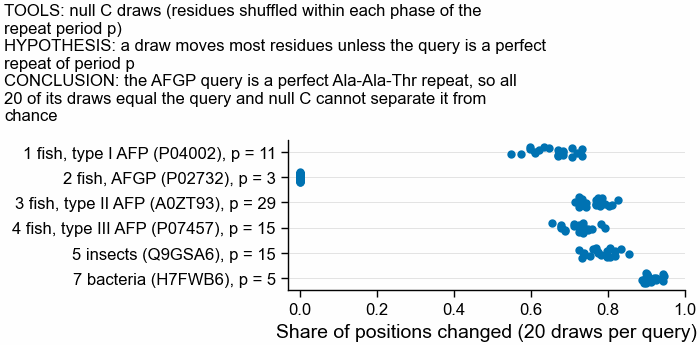

In [2]:
periods = (
    null_c.group_by(
        "accession", "lineage", "unit_length", "unit_source", maintain_order=True
    )
    .agg(
        median_share_of_positions_moved=pl.col("frac_positions_changed").median(),
        draws_identical_to_query=(pl.col("frac_positions_changed") == 0).sum(),
    )
    .rename({"unit_length": "period_p"})
)
print(periods)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 45)
for i, r in enumerate(periods.iter_rows(named=True)):
    vals = null_c.filter(pl.col("accession") == r["accession"])[
        "frac_positions_changed"
    ]
    ax.plot(
        vals,
        np.full(len(vals), i) + np.linspace(-0.2, 0.2, len(vals)),
        "o",
        color=pf.OKABE_ITO["blue"],
        markersize=2,
        linestyle="none",
    )
ax.set_yticks(
    range(periods.height),
    [
        f"{r['lineage']} ({r['accession']}), p = {r['period_p']}"
        for r in periods.iter_rows(named=True)
    ],
)
ax.invert_yaxis()
ax.set_xlim(-0.03, 1.0)
ax.set_xlabel("Share of positions changed (20 draws per query)")
for y in range(periods.height):
    ax.axhline(y, color="#dddddd", linewidth=0.3, zorder=0)
header(
    fig,
    "null C draws (residues shuffled within each phase of the repeat period p)",
    "a draw moves most residues unless the query is a perfect repeat of period p",
    "the AFGP query is a perfect Ala-Ala-Thr repeat, so all 20 of its draws equal the "
    "query and null C cannot separate it from chance",
)
pf.save(fig, FIGURES / "298_SF0_null_c_positions_moved")

## 2. Choosing one setting on four lineages

The rule from the first cell, applied to the real queries of lineages 1, 3, 5 and 7 at 2
shared keys. The table below ranks every setting: eligible ones (random share at most 1%
on each of the four queries) first, then by mean reach. Below it, the full grid: every
setting against every real query, written also to `298_grid_real_queries_2_shared_keys.tsv`.

11 of the 210 settings pass the 1% bar on all four queries: six with the 20 amino acids,
one with Dayhoff and four hydrophobic-polar ones, all of those with 10-letter words, one
pair per position and the spacing in the key. Every two-letter key with shorter words
fails the bar on at least one of the four queries. In Dayhoff, alanine and threonine are one class, so the AFGP query has a
single distinct key in 12 Dayhoff settings and can never share 2: those rows read 0 of 55.

210 settings; 11 keep the random share at most 1% on all four selection queries
Top of the ranking (eligible first):
shape: (12, 8)
┌──────────────────────────┬─────────────┬──────────────────┬────────────┬──────────────────┬───────────────────┬───────────┬──────────┐
│ alphabet                 ┆ word_length ┆ family           ┆ mean_reach ┆ max_random_share ┆ mean_random_share ┆ n_queries ┆ eligible │
│ ---                      ┆ ---         ┆ ---              ┆ ---        ┆ ---              ┆ ---               ┆ ---       ┆ ---      │
│ str                      ┆ i64         ┆ str              ┆ f64        ┆ f64              ┆ f64               ┆ u32       ┆ bool     │
╞══════════════════════════╪═════════════╪══════════════════╪════════════╪══════════════════╪═══════════════════╪═══════════╪══════════╡
│ protein20                ┆ 4           ┆ pair_gapbin3     ┆ 0.032592   ┆ 0.005            ┆ 0.0013            ┆ 4         ┆ true     │
│ protein20                ┆ 4           ┆ pai

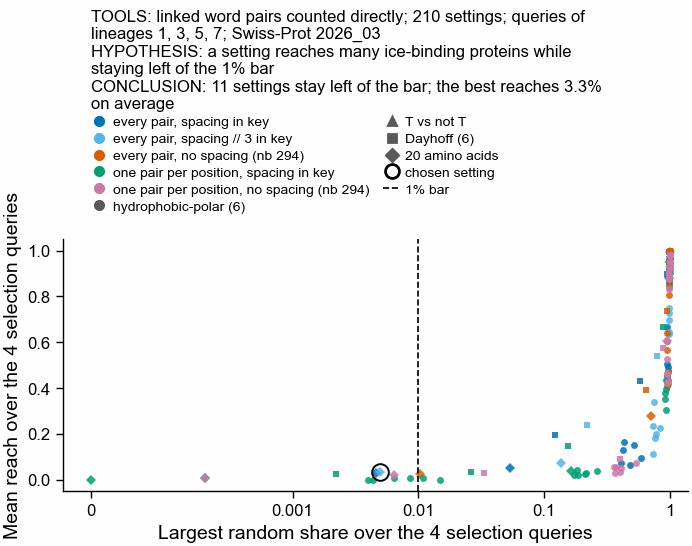

In [3]:
real2 = reach.filter(
    (pl.col("kind") == "real") & (pl.col("min_shared") == sr.RULE_MIN_SHARED)
)
table = sr.selection_table(reach)
eligible = table.filter(pl.col("eligible"))
print(
    f"{table.height} settings; {eligible.height} keep the random share at most "
    f"{sr.RANDOM_SHARE_BAR:.0%} on all four selection queries"
)
print("Top of the ranking (eligible first):")
print(table.head(12))
chosen = table.row(0, named=True)
chosen_by_rule = bool(chosen["eligible"])
CHOSEN = {k: chosen[k] for k in sr.SETTING}
print(f"\nchosen setting: {CHOSEN}, by the rule: {chosen_by_rule}")

# The full grid: every setting, every real query, at 2 shared keys.
grid = (
    real2.with_columns(
        cell=pl.format(
            "{}/{} ({})",
            pl.col("targets_reached"),
            pl.col("targets_total"),
            (pl.col("random_share") * 100).round(2).cast(pl.String) + "%",
        )
    )
    .pivot(on="lineage", index=sr.SETTING, values="cell")
    .sort(sr.SETTING)
)
grid.write_csv(D / "298_grid_real_queries_2_shared_keys.tsv", separator="\t")
print(
    "\nEvery setting: targets reached / other-lineage targets (random share), "
    "real queries, 2 shared keys"
)
with pl.Config(tbl_rows=-1):
    print(grid)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
tab = table.with_columns(
    group=pl.col("alphabet").map_elements(alphabet_group, pl.String)
)
for fam, colour in FAMILY_COLOUR.items():
    for grp, marker in GROUP_MARKER.items():
        f = tab.filter((pl.col("family") == fam) & (pl.col("group") == grp))
        ax.plot(
            np.where(f["max_random_share"] == 0, 2.5e-5, f["max_random_share"]),
            f["mean_reach"],
            marker,
            color=colour,
            markersize=2.5,
            markeredgewidth=0,
            alpha=0.85,
            linestyle="none",
        )
ax.plot(
    max(chosen["max_random_share"], 2.5e-5),
    chosen["mean_reach"],
    "o",
    markersize=6,
    markerfacecolor="none",
    markeredgecolor="black",
    markeredgewidth=0.7,
)
ax.axvline(sr.RANDOM_SHARE_BAR, color="black", linestyle="--", linewidth=0.6)
ax.set_xscale("log")
ax.set_xlim(1.5e-5, 1.4)
ax.set_xticks([2.5e-5, 1e-3, 1e-2, 1e-1, 1], ["0", "0.001", "0.01", "0.1", "1"])
ax.minorticks_off()
ax.set_xlabel("Largest random share over the 4 selection queries")
ax.set_ylabel("Mean reach over the 4 selection queries")
handles = [
    Line2D(
        [],
        [],
        marker="o",
        color=c,
        linestyle="none",
        markersize=3,
        label=FAMILY_LABEL[f],
    )
    for f, c in FAMILY_COLOUR.items()
]
handles += [
    Line2D([], [], marker=m, color="#555555", linestyle="none", markersize=3, label=g)
    for g, m in GROUP_MARKER.items()
]
handles += [
    Line2D(
        [],
        [],
        marker="o",
        markerfacecolor="none",
        markeredgecolor="black",
        linestyle="none",
        markersize=5,
        label="chosen setting",
    ),
    Line2D([], [], color="black", linestyle="--", linewidth=0.6, label="1% bar"),
]
header(
    fig,
    "linked word pairs counted directly; 210 settings; queries of lineages 1, 3, 5, 7; "
    "Swiss-Prot 2026_03",
    "a setting reaches many ice-binding proteins while staying left of the 1% bar",
    f"{eligible.height} settings stay left of the bar; the best reaches "
    f"{chosen['mean_reach']:.1%} on average",
    handles=handles,
    ncol=2,
)
pf.save(fig, FIGURES / "298_SF3_selection_mean_reach_vs_random_share_swissprot_2026_03")

## 3. F1: reach against the random share, every setting

One panel per real query. Each point is one setting at 2 shared keys: across, the share of
5_000 random Swiss-Prot entries that share at least 2 keys with the query; up, the share of
other-lineage ice-binding proteins that do. Grey points are section 9's exact k-mers. A
useful key sits high and to the left of the dashed line at 1%. A point on the dotted line
finds ice-binding proteins no more often than any protein. The ring marks the setting the
rule chose. Lineages 2 and 4 are held out: they played no part in the choice.

shape: (29, 8)
┌──────────────────────┬──────────────────┬───────────┬─────────────┬─────────────────┬───────────────┬──────────┬──────────────┐
│ lineage              ┆ family           ┆ alphabet  ┆ word_length ┆ targets_reached ┆ targets_total ┆ reach    ┆ random_share │
│ ---                  ┆ ---              ┆ ---       ┆ ---         ┆ ---             ┆ ---           ┆ ---      ┆ ---          │
│ str                  ┆ str              ┆ str       ┆ i64         ┆ i64             ┆ i64           ┆ f64      ┆ f64          │
╞══════════════════════╪══════════════════╪═══════════╪═════════════╪═════════════════╪═══════════════╪══════════╪══════════════╡
│ 1 fish, type I AFP   ┆ pair_gap         ┆ protein20 ┆ 4           ┆ 1               ┆ 47            ┆ 0.021277 ┆ 0.0046       │
│ 1 fish, type I AFP   ┆ pair_gapbin3     ┆ protein20 ┆ 4           ┆ 1               ┆ 47            ┆ 0.021277 ┆ 0.005        │
│ 1 fish, type I AFP   ┆ randstrobe_gap   ┆ protein20 ┆ 3           ┆ 0    

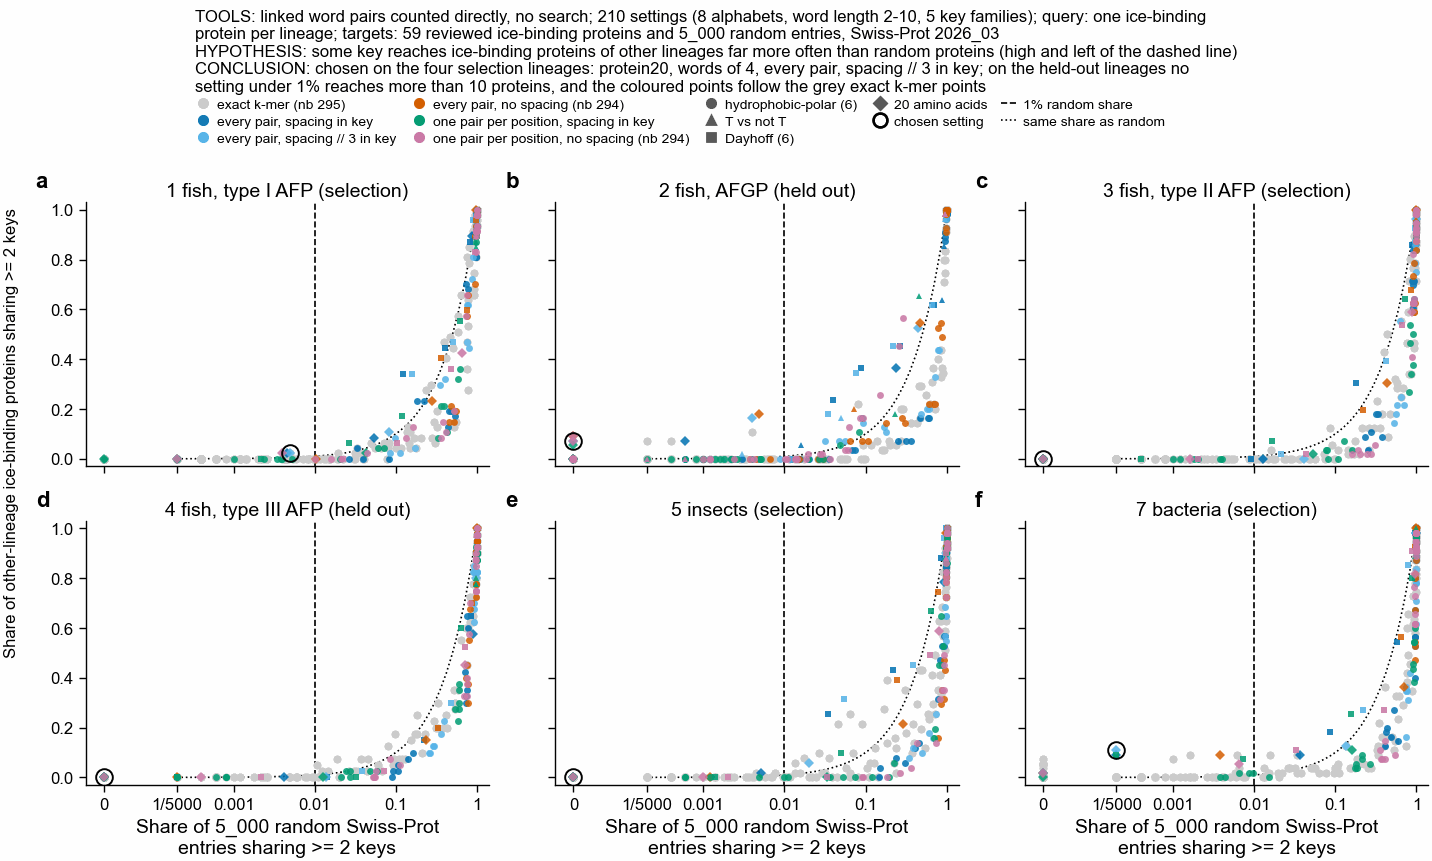

In [4]:
def xpos(share):
    """Random share on the log axis; 0 is drawn at 1/40_000, well left of 1/5_000."""
    return np.where(share == 0, 2.5e-5, share)


exact_q = exact.rename({"query_lineage": "lineage"})
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 110, nrows=2, ncols=3, sharex=True, sharey=True)
for ax, lin in zip(axs.ravel(), LINEAGES):
    e = exact_q.filter(pl.col("lineage") == lin)
    ax.plot(
        xpos(e["frac_background_reachable"].to_numpy()),
        e["frac_cross_reachable"],
        "o",
        color="#cccccc",
        markersize=2,
        linestyle="none",
        zorder=1,
        label="exact k-mer, k = 3-40 (nb 295 section 9)",
    )
    sub = real2.filter(pl.col("lineage") == lin)
    for fam, colour in FAMILY_COLOUR.items():
        for grp, marker in GROUP_MARKER.items():
            f = sub.filter(
                (pl.col("family") == fam)
                & (pl.col("alphabet").map_elements(alphabet_group, pl.String) == grp)
            )
            ax.plot(
                xpos(f["random_share"].to_numpy()),
                f["reach"],
                marker,
                color=colour,
                markersize=2.5,
                markeredgewidth=0,
                alpha=0.85,
                linestyle="none",
                zorder=2,
            )
    c = sub.filter(
        (pl.col("alphabet") == CHOSEN["alphabet"])
        & (pl.col("word_length") == CHOSEN["word_length"])
        & (pl.col("family") == CHOSEN["family"])
    )
    ax.plot(
        xpos(c["random_share"].to_numpy()),
        c["reach"],
        "o",
        markersize=6,
        markerfacecolor="none",
        markeredgecolor="black",
        markeredgewidth=0.7,
        zorder=3,
    )
    xs = np.logspace(np.log10(2e-4), 0, 50)
    ax.plot(xs, xs, ":", color="black", linewidth=0.6, zorder=0)
    ax.axvline(
        sr.RANDOM_SHARE_BAR, color="black", linestyle="--", linewidth=0.6, zorder=0
    )
    held = " (held out)" if lin in sr.REPORT_LINEAGES else " (selection)"
    ax.set_title(lin + held, pad=2)
    ax.set_xscale("log")
    ax.set_xlim(1.5e-5, 1.4)
    ax.set_ylim(-0.03, 1.03)
    ax.set_xticks(
        [2.5e-5, 2e-4, 1e-3, 1e-2, 1e-1, 1],
        ["0", "1/5000", "0.001", "0.01", "0.1", "1"],
    )
    ax.minorticks_off()
for ax, letter in zip(axs.ravel(), "abcdef"):
    pf.panel_label(ax, letter)
for ax in axs[1]:
    ax.set_xlabel("Share of 5_000 random Swiss-Prot\nentries sharing >= 2 keys")
fig.supylabel(
    "Share of other-lineage ice-binding proteins sharing >= 2 keys", fontsize=6
)
handles = (
    [
        Line2D(
            [],
            [],
            marker="o",
            color="#cccccc",
            linestyle="none",
            markersize=3,
            label="exact k-mer (nb 295)",
        ),
    ]
    + [
        Line2D(
            [],
            [],
            marker="o",
            color=c,
            linestyle="none",
            markersize=3,
            label=FAMILY_LABEL[f],
        )
        for f, c in FAMILY_COLOUR.items()
    ]
    + [
        Line2D(
            [], [], marker=m, color="#555555", linestyle="none", markersize=3, label=g
        )
        for g, m in GROUP_MARKER.items()
    ]
    + [
        Line2D(
            [],
            [],
            marker="o",
            markerfacecolor="none",
            markeredgecolor="black",
            linestyle="none",
            markersize=5,
            label="chosen setting"
            + ("" if chosen_by_rule else " (no setting passed the 1% bar)"),
        ),
        Line2D(
            [],
            [],
            color="black",
            linestyle="--",
            linewidth=0.6,
            label="1% random share",
        ),
        Line2D(
            [],
            [],
            color="black",
            linestyle=":",
            linewidth=0.6,
            label="same share as random",
        ),
    ]
)
best_held = real2.filter(
    pl.col("lineage").is_in(sr.REPORT_LINEAGES)
    & (pl.col("random_share") <= sr.RANDOM_SHARE_BAR)
)
header(
    fig,
    "linked word pairs counted directly, no search; 210 settings (8 alphabets, word length "
    "2-10, 5 key families); query: one ice-binding protein per lineage; targets: 59 reviewed "
    "ice-binding proteins and 5_000 random entries, Swiss-Prot 2026_03",
    "some key reaches ice-binding proteins of other lineages far more often than random "
    "proteins (high and left of the dashed line)",
    f"chosen on the four selection lineages: {CHOSEN['alphabet']}, words of "
    f"{CHOSEN['word_length']}, {FAMILY_LABEL[CHOSEN['family']]}; on the held-out lineages "
    f"no setting under 1% reaches more than {int(best_held['targets_reached'].max())} proteins, "
    "and the coloured points follow the grey exact k-mer points",
    handles=handles,
    ncol=5,
)
pf.save(fig, FIGURES / "298_F1_linked_pair_reach_vs_random_swissprot_2026_03")

# The points, as a table: the best setting per query and family under the 1% bar.
print(
    real2.filter(pl.col("random_share") <= sr.RANDOM_SHARE_BAR)
    .sort("reach", descending=True)
    .group_by("lineage", "family", maintain_order=True)
    .head(1)
    .select(
        "lineage",
        "family",
        "alphabet",
        "word_length",
        "targets_reached",
        "targets_total",
        "reach",
        "random_share",
    )
    .sort("lineage", "family")
)

## 4. The decision

The rule's numbers for the two held-out lineages. The best exact k-mer is read from
section 9's table with the same 1% bar. AFGP: the chosen key reaches 4 of 55 (7.3%), the
best exact k-mer (20 amino acids, k = 4) 6 of 55 (10.9%), a margin of -3.6 points; the
residue-shuffled copies (null A) reach a median of 8 of 55 (14.5%), more than the real
query. Fish type III: 0 of 40 for the chosen key and for every exact k-mer under the bar.
Both parts of the rule fail on both lineages.

Choosing a setting by looking at the held-out queries, which the rule forbids, would not
change this: the best setting under 1% on AFGP reaches 10 of 55 (the 20 amino acids,
3-letter words, every pair, no spacing), 7.3 points above the best exact k-mer, still short
of 10, and on fish type III no setting under 1% reaches any target.

shape: (2, 13)
┌─────────────────┬────────┬──────────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┬──────────────┬──────────────┬──────────────┬────────────────┬──────────┬───────────┐
│ lineage         ┆ query  ┆ chosen_reach ┆ chosen_random_s ┆ best_exact_k_me ┆ best_exact_reac ┆ margin_over_exa ┆ median_nullA ┆ median_nullB ┆ median_nullC ┆ margin_over_nu ┆ i_passes ┆ ii_passes │
│ ---             ┆ ---    ┆ ---          ┆ hare            ┆ r               ┆ h               ┆ ct              ┆ ---          ┆ ---          ┆ ---          ┆ llC            ┆ ---      ┆ ---       │
│ str             ┆ str    ┆ f64          ┆ ---             ┆ ---             ┆ ---             ┆ ---             ┆ f64          ┆ f64          ┆ f64          ┆ ---            ┆ bool     ┆ bool      │
│                 ┆        ┆              ┆ f64             ┆ str             ┆ f64             ┆ f64             ┆              ┆              ┆              ┆ f64            ┆    

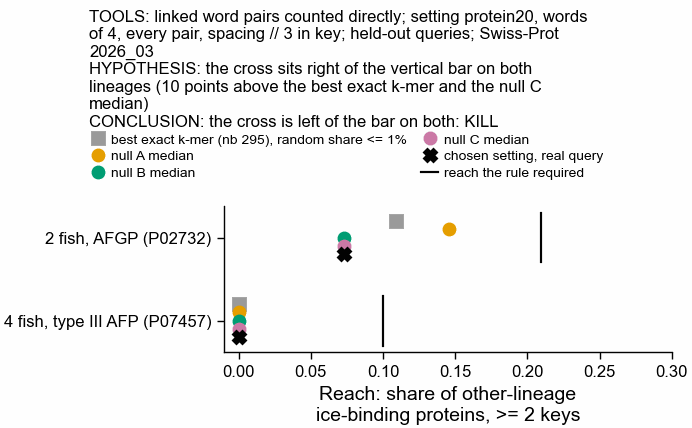

In [5]:
def held_out_row(lin):
    """The decision's numbers for one held-out lineage."""
    e = exact.filter(
        (pl.col("query_lineage") == lin)
        & (pl.col("frac_background_reachable") <= sr.RANDOM_SHARE_BAR)
    ).sort("frac_cross_reachable", descending=True)
    best_exact = e.row(0, named=True)
    s = reach.filter(
        (pl.col("lineage") == lin)
        & (pl.col("min_shared") == sr.RULE_MIN_SHARED)
        & (pl.col("alphabet") == CHOSEN["alphabet"])
        & (pl.col("word_length") == CHOSEN["word_length"])
        & (pl.col("family") == CHOSEN["family"])
    )
    real = s.filter(pl.col("kind") == "real").row(0, named=True)
    med = {
        k: s.filter(pl.col("kind") == k)["reach"].median()
        for k in ["nullA", "nullB", "nullC"]
    }
    margin_exact = real["reach"] - best_exact["frac_cross_reachable"]
    margin_c = real["reach"] - med["nullC"]
    return {
        "lineage": lin,
        "query": real["query"],
        "chosen_reach": real["reach"],
        "chosen_random_share": real["random_share"],
        "best_exact_k_mer": f"{best_exact['alphabet']} k={best_exact['ksize']}",
        "best_exact_reach": best_exact["frac_cross_reachable"],
        "margin_over_exact": margin_exact,
        "median_nullA": med["nullA"],
        "median_nullB": med["nullB"],
        "median_nullC": med["nullC"],
        "margin_over_nullC": margin_c,
        "i_passes": margin_exact >= sr.MARGIN,
        "ii_passes": bool(
            margin_c >= sr.MARGIN
            and real["reach"] > med["nullA"]
            and real["reach"] > med["nullB"]
        ),
    }


decision = pl.DataFrame([held_out_row(lin) for lin in sr.REPORT_LINEAGES])
with pl.Config(tbl_cols=-1):
    print(decision)
stage1_pass = chosen_by_rule and bool(
    decision["i_passes"].all() and decision["ii_passes"].all()
)
print(f"\nchosen by the rule: {chosen_by_rule}")
print(f"STAGE 1: {'PASS, stage 2 runs' if stage1_pass else 'KILL, no search runs'}")

ITEMS = [
    (
        "best exact k-mer (nb 295), random share <= 1%",
        "best_exact_reach",
        "s",
        "#999999",
    ),
    ("null A median", "median_nullA", "o", pf.OKABE_ITO["orange"]),
    ("null B median", "median_nullB", "o", pf.OKABE_ITO["bluish_green"]),
    ("null C median", "median_nullC", "o", pf.OKABE_ITO["reddish_purple"]),
    ("chosen setting, real query", "chosen_reach", "X", "black"),
]
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
for i, r in enumerate(decision.iter_rows(named=True)):
    for j, (label, col, marker, colour) in enumerate(ITEMS):
        ax.plot(
            r[col],
            i + (j - 2) * 0.1,
            marker,
            color=colour,
            markersize=4,
            linestyle="none",
            label=label if i == 0 else None,
        )
    bar = max(r["best_exact_reach"], r["median_nullC"]) + sr.MARGIN
    ax.plot(
        [bar, bar],
        [i - 0.3, i + 0.3],
        color="black",
        linewidth=0.8,
        label="reach the rule required" if i == 0 else None,
    )
ax.set_yticks(
    range(decision.height),
    [f"{r['lineage']} ({r['query']})" for r in decision.iter_rows(named=True)],
)
ax.invert_yaxis()
ax.set_xlim(-0.01, 0.3)
ax.set_xlabel("Reach: share of other-lineage\nice-binding proteins, >= 2 keys")
handles, labels = ax.get_legend_handles_labels()
header(
    fig,
    f"linked word pairs counted directly; setting {CHOSEN['alphabet']}, words of "
    f"{CHOSEN['word_length']}, {FAMILY_LABEL[CHOSEN['family']]}; held-out queries; "
    "Swiss-Prot 2026_03",
    "the cross sits right of the vertical bar on both lineages (10 points above the best "
    "exact k-mer and the null C median)",
    "the cross is left of the bar on both: KILL",
    handles=handles,
    ncol=2,
)
pf.save(fig, FIGURES / "298_SF4_decision_held_out_lineages_swissprot_2026_03")

## 5. SF1: the chosen setting against its own null draws

For the chosen setting, each real query's reach (black cross) beside its 20 null A draws
(residues shuffled), 20 null B draws (the repeat period kept, the word inside each repeat
reordered) and 20 null C draws (residues shuffled within each repeat phase). A real query
level with its draws means the setting's reach does not depend on the query's order.

shape: (24, 6)
┌──────────────────────┬───────┬──────────────┬───────────┬───────────┬─────┐
│ lineage              ┆ kind  ┆ median_reach ┆ min_reach ┆ max_reach ┆ n   │
│ ---                  ┆ ---   ┆ ---          ┆ ---       ┆ ---       ┆ --- │
│ str                  ┆ str   ┆ f64          ┆ f64       ┆ f64       ┆ u32 │
╞══════════════════════╪═══════╪══════════════╪═══════════╪═══════════╪═════╡
│ 1 fish, type I AFP   ┆ nullA ┆ 0.0          ┆ 0.0       ┆ 0.042553  ┆ 20  │
│ 1 fish, type I AFP   ┆ nullB ┆ 0.042553     ┆ 0.0       ┆ 0.042553  ┆ 20  │
│ 1 fish, type I AFP   ┆ nullC ┆ 0.010638     ┆ 0.0       ┆ 0.06383   ┆ 20  │
│ 1 fish, type I AFP   ┆ real  ┆ 0.021277     ┆ 0.021277  ┆ 0.021277  ┆ 1   │
│ 2 fish, AFGP         ┆ nullA ┆ 0.145455     ┆ 0.090909  ┆ 0.163636  ┆ 20  │
│ 2 fish, AFGP         ┆ nullB ┆ 0.072727     ┆ 0.072727  ┆ 0.090909  ┆ 20  │
│ 2 fish, AFGP         ┆ nullC ┆ 0.072727     ┆ 0.072727  ┆ 0.072727  ┆ 20  │
│ 2 fish, AFGP         ┆ real  ┆ 0.072727     ┆ 0

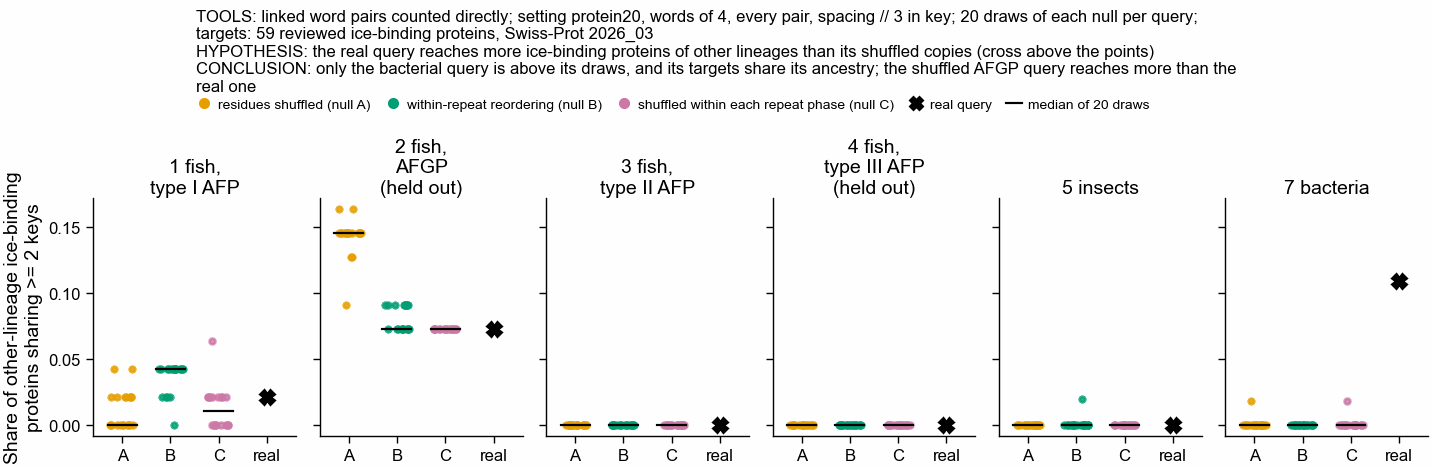

In [6]:
KIND_STYLE = {
    "nullA": ("residues shuffled (null A)", pf.OKABE_ITO["orange"]),
    "nullB": ("within-repeat reordering (null B)", pf.OKABE_ITO["bluish_green"]),
    "nullC": (
        "shuffled within each repeat phase (null C)",
        pf.OKABE_ITO["reddish_purple"],
    ),
}
s = reach.filter(
    (pl.col("min_shared") == sr.RULE_MIN_SHARED)
    & (pl.col("alphabet") == CHOSEN["alphabet"])
    & (pl.col("word_length") == CHOSEN["word_length"])
    & (pl.col("family") == CHOSEN["family"])
)
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 60, ncols=6, sharey=True)
rng = np.random.default_rng(0)
for ax, lin in zip(axs, LINEAGES):
    q = s.filter(pl.col("lineage") == lin)
    for x, (kind, (label, colour)) in enumerate(KIND_STYLE.items()):
        v = q.filter(pl.col("kind") == kind)["reach"].to_numpy()
        ax.plot(
            x + rng.uniform(-0.25, 0.25, v.size),
            v,
            "o",
            color=colour,
            markersize=2,
            alpha=0.8,
            linestyle="none",
            label=label,
        )
        ax.plot([x - 0.3, x + 0.3], [np.median(v)] * 2, color="black", linewidth=0.8)
    rv = q.filter(pl.col("kind") == "real")["reach"][0]
    ax.plot(
        3, rv, "X", color="black", markersize=5, linestyle="none", label="real query"
    )
    ax.set_xticks(range(4), ["A", "B", "C", "real"])
    ax.set_xlim(-0.6, 3.6)
    ax.set_title(
        lin.replace(", ", ",\n")
        + ("\n(held out)" if lin in sr.REPORT_LINEAGES else ""),
        pad=2,
    )
axs[0].set_ylabel("Share of other-lineage ice-binding\nproteins sharing >= 2 keys")
handles = [
    Line2D([], [], marker="o", color=c, linestyle="none", markersize=3, label=l)
    for l, c in KIND_STYLE.values()
]
handles += [
    Line2D(
        [],
        [],
        marker="X",
        color="black",
        linestyle="none",
        markersize=4,
        label="real query",
    ),
    Line2D([], [], color="black", linewidth=0.8, label="median of 20 draws"),
]
header(
    fig,
    f"linked word pairs counted directly; setting {CHOSEN['alphabet']}, words of "
    f"{CHOSEN['word_length']}, {FAMILY_LABEL[CHOSEN['family']]}; 20 draws of each null per "
    "query; targets: 59 reviewed ice-binding proteins, Swiss-Prot 2026_03",
    "the real query reaches more ice-binding proteins of other lineages than its shuffled "
    "copies (cross above the points)",
    "only the bacterial query is above its draws, and its targets share its ancestry; the "
    "shuffled AFGP query reaches more than the real one",
    handles=handles,
    ncol=5,
)
pf.save(fig, FIGURES / "298_SF1_chosen_setting_real_vs_null_draws_swissprot_2026_03")
print(
    s.group_by("lineage", "kind")
    .agg(
        median_reach=pl.col("reach").median(),
        min_reach=pl.col("reach").min(),
        max_reach=pl.col("reach").max(),
        n=pl.len(),
    )
    .sort("lineage", "kind")
)

## 6. SF2: how often keys match by chance, and what that means for a database

Over the 6 real queries: the mean number of keys a random Swiss-Prot entry shares with the
query (top) and the share of random entries sharing at least 2 (bottom), by word length,
one line per alphabet and one panel per key family. Multiplied by Swiss-Prot's 575_748
entries, the bottom row is how many entries a search would have to rank before any filter
on score. This is the chance-match number [PR 143](https://github.com/seanome/2024-kmerseek-analysis/pull/143)
listed as untested; the table is `data/convergence_afp/298_strobemer_chance_cost.tsv`, and
notebook 294's key (hp_thomas_dill2, a = 6, every pair, no spacing) is ringed.

Mean over the 6 real queries; Swiss-Prot 2026_03 has 575748 entries
shape: (210, 8)
┌──────────────────────────┬─────────────┬──────────────────┬─────────────────┬───────────────────────────────────┬─────────────────────┬──────────────────────────────────────┬──────────────────┐
│ alphabet                 ┆ word_length ┆ family           ┆ mean_query_keys ┆ mean_shared_keys_per_random_entry ┆ random_share_2_keys ┆ swissprot_entries_expected_at_2_keys ┆ nb294_chosen_key │
│ ---                      ┆ ---         ┆ ---              ┆ ---             ┆ ---                               ┆ ---                 ┆ ---                                  ┆ ---              │
│ str                      ┆ i64         ┆ str              ┆ f64             ┆ f64                               ┆ f64                 ┆ f64                                  ┆ bool             │
╞══════════════════════════╪═════════════╪══════════════════╪═════════════════╪═══════════════════════════════════╪═════════════════

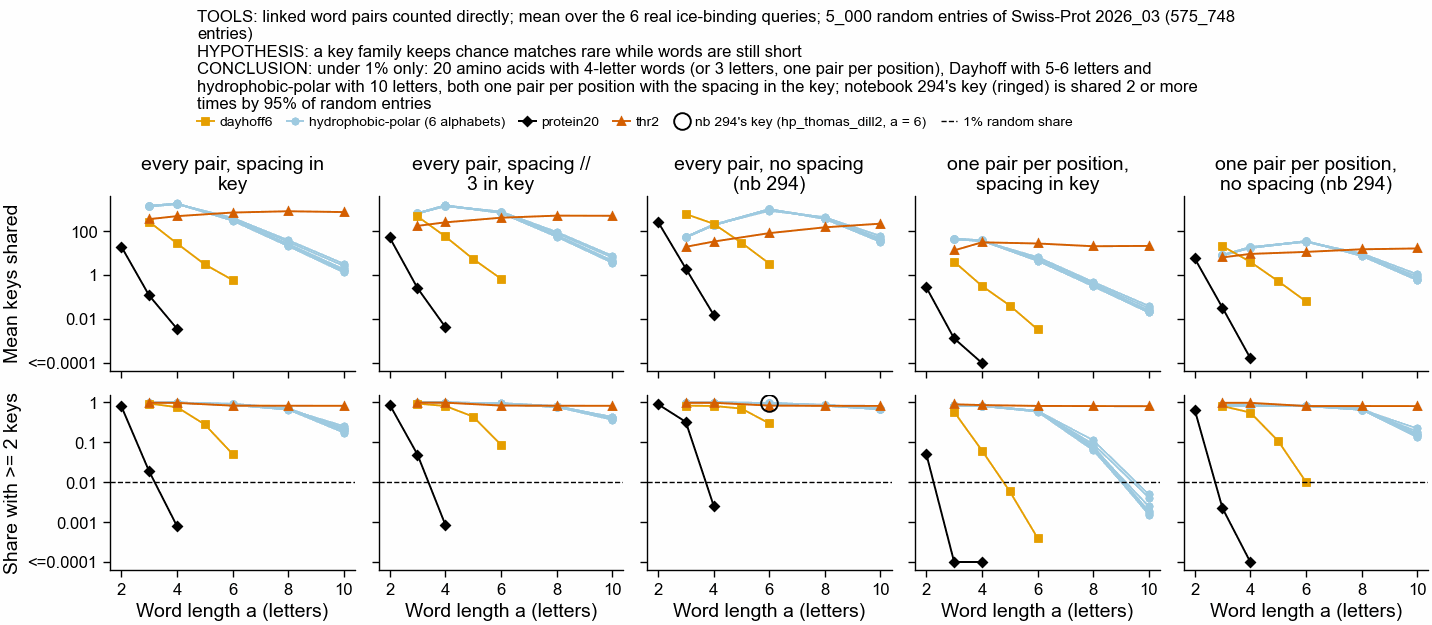

In [7]:
real_all = reach.filter(pl.col("kind") == "real")
cost = (
    real_all.group_by(sr.SETTING + ["min_shared"])
    .agg(
        mean_random_share=pl.col("random_share").mean(),
        mean_shared_keys_per_random_entry=pl.col(
            "mean_shared_keys_per_random_entry"
        ).mean(),
        mean_query_keys=pl.col("query_keys").mean(),
    )
    .pivot(
        on="min_shared",
        index=sr.SETTING + ["mean_shared_keys_per_random_entry", "mean_query_keys"],
        values="mean_random_share",
    )
    .rename(
        {
            "1": "random_share_1_key",
            "2": "random_share_2_keys",
            "3": "random_share_3_keys",
        }
    )
    .with_columns(
        swissprot_entries_expected_at_2_keys=(
            pl.col("random_share_2_keys") * N_SWISSPROT
        ).round(0),
        nb294_chosen_key=(pl.col("alphabet") == "hp_thomas_dill2")
        & (pl.col("word_length") == 6)
        & (pl.col("family") == "pair_nogap"),
    )
    .sort(sr.SETTING)
)
cost.write_csv(D / "298_strobemer_chance_cost.tsv", separator="\t")
print("Mean over the 6 real queries; Swiss-Prot 2026_03 has", N_SWISSPROT, "entries")
with pl.Config(tbl_rows=-1):
    print(
        cost.select(
            sr.SETTING
            + [
                "mean_query_keys",
                "mean_shared_keys_per_random_entry",
                "random_share_2_keys",
                "swissprot_entries_expected_at_2_keys",
                "nb294_chosen_key",
            ]
        )
    )

nb294_share = cost.filter(pl.col("nb294_chosen_key"))["random_share_2_keys"][0]
ALPHA_STYLE = {
    "protein20": (pf.OKABE_ITO["black"], "D"),
    "dayhoff6": (pf.OKABE_ITO["orange"], "s"),
    "thr2": (pf.OKABE_ITO["vermillion"], "^"),
}
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 80, nrows=2, ncols=5, sharex=True, sharey="row")
for j, fam in enumerate(FAMILY_COLOUR):
    f = cost.filter(pl.col("family") == fam)
    for alpha in f["alphabet"].unique().sort():
        g = f.filter(pl.col("alphabet") == alpha).sort("word_length")
        colour, marker = ALPHA_STYLE.get(alpha, ("#9ecae1", "o"))
        lab = alpha if alpha in ALPHA_STYLE else "hydrophobic-polar (6 alphabets)"
        z = 1 if alpha.startswith("hp_") else 2
        axs[0, j].plot(
            g["word_length"],
            g["mean_shared_keys_per_random_entry"].clip(1e-4, None),
            marker=marker,
            color=colour,
            markersize=2,
            linewidth=0.7,
            zorder=z,
            label=lab,
        )
        axs[1, j].plot(
            g["word_length"],
            g["random_share_2_keys"].clip(1e-4, None),
            marker=marker,
            color=colour,
            markersize=2,
            linewidth=0.7,
            zorder=z,
            label=lab,
        )
    axs[0, j].set_title(textwrap.fill(FAMILY_LABEL[fam], 22), pad=2)
    axs[1, j].axhline(sr.RANDOM_SHARE_BAR, color="black", linestyle="--", linewidth=0.5)
    axs[1, j].set_xlabel("Word length a (letters)")
    nb = cost.filter(pl.col("nb294_chosen_key") & (pl.col("family") == fam))
    for r in nb.iter_rows(named=True):
        axs[1, j].plot(
            r["word_length"],
            max(r["random_share_2_keys"], 1e-4),
            "o",
            markersize=6,
            markerfacecolor="none",
            markeredgecolor="black",
            markeredgewidth=0.7,
            label="nb 294's key (hp_thomas_dill2, a = 6)",
        )
for ax in axs.ravel():
    ax.set_yscale("log")
    ax.minorticks_off()
    ax.set_xticks([2, 4, 6, 8, 10])
axs[0, 0].set_yticks([1e-4, 1e-2, 1, 100], ["<=0.0001", "0.01", "1", "100"])
axs[1, 0].set_yticks(
    [1e-4, 1e-3, 1e-2, 1e-1, 1], ["<=0.0001", "0.001", "0.01", "0.1", "1"]
)
axs[0, 0].set_ylabel("Mean keys shared")
axs[1, 0].set_ylabel("Share with >= 2 keys")
handles, labels = [], []
for ax in axs.ravel():
    for h, l in zip(*ax.get_legend_handles_labels()):
        if l not in labels:
            handles.append(h)
            labels.append(l)
handles.append(Line2D([], [], color="black", linestyle="--", linewidth=0.5))
labels.append("1% random share")
for h, l in zip(handles, labels):
    h.set_label(l)
header(
    fig,
    "linked word pairs counted directly; mean over the 6 real ice-binding queries; "
    "5_000 random entries of Swiss-Prot 2026_03 (575_748 entries)",
    "a key family keeps chance matches rare while words are still short",
    "under 1% only: 20 amino acids with 4-letter words (or 3 letters, one pair per "
    "position), Dayhoff with 5-6 letters and hydrophobic-polar with 10 letters, both one "
    "pair per position with the spacing in the key; notebook 294's key (ringed) is shared "
    f"2 or more times by {nb294_share:.0%} of random entries",
    handles=handles,
    ncol=6,
)
pf.save(fig, FIGURES / "298_SF2_linked_pair_chance_cost_swissprot_2026_03")

## 7. The residues behind the shared keys

The chosen setting reaches 11 pairs of a query and an ice-binding protein of another
lineage, from three of the six queries. All are printed below; the reading is:

* Bacterial query H7FWB6 against five fungal proteins (B8XC03, B8XC04, C7F6X3, Q76CE6,
  Q76CE8). UniProt puts the query and all five in its "Ice-binding protein family". Over
  the stretch from the first word to the second, where the spacing is equal in both, the
  median identity per pair is 54 to 66% (for example 25 of 42 residues with B8XC03).
  This is ancestry, which notebook 295 found too (its F3), not a pattern reached without
  it.
* Bacterial query H7FWB6 against P05140 (fish type II): 2 shared keys, `KILK` and `ETTA`
  about 31 residues apart in both, in otherwise unrelated sequence. One chance match at
  the bar.
* AFGP query P02732 against four fish type I proteins (B1P0S1, P02734, P07835, P23699),
  and the type I query P04002 against the AFGP polyprotein P24856: every shared word is
  made of alanine and threonine (`AATA`, `ATAA`, `TAAT`), plus proline in the type I
  pair (`AAPA`, `APAA`). Both lineages are alanine-rich with threonine at intervals. The
  AFGP query's residue-shuffled copies (null A) reach more ice-binding proteins of other
  lineages than the real query does (SF1), so the order of the residues adds nothing to
  these matches.

Each key is printed as the stretch from the first word's start to the second word's end,
in both sequences, with coordinates (1-based, inclusive), the alphabet's classes
underneath, and `^` under the two words. Only the words must match; the residues between
them are free. Up to 6 keys per pair are shown.

In [8]:
keys = pl.read_csv(D / "298_chosen_setting_shared_keys.tsv", separator="\t")
needed = set(keys["query"]) | set(keys["target"])
seqs = {}
for name, s_ in ceiling.read_fasta(ceiling.SPROT).items():
    if name in needed:
        seqs[name] = s_
tab = sr.table(CHOSEN["alphabet"])
letters = "".join(chr(97 + i) for i in range(sr.base(CHOSEN["alphabet"])))
print(
    f"setting: {CHOSEN}; classes: "
    + ", ".join(
        f"{letters[i]} = {''.join(sorted(c))}"
        for i, c in enumerate(sr.CLUSTERS[CHOSEN["alphabet"]])
    )
)


def enc(s):
    return "".join(
        "*" if c == sr.GAP else letters[c]
        for c in tab[np.frombuffer(s.encode(), np.uint8)]
    )


a = CHOSEN["word_length"]
for (q, t), g in keys.group_by(["query", "target"], maintain_order=True):
    r0 = g.row(0, named=True)
    print(
        f"\n=== query {q} ({r0['query_lineage']}) vs {t} ({r0['target_kind']}): "
        f"{r0['n_shared_keys']} shared keys"
    )
    for r in g.head(6).iter_rows(named=True):
        out = []
        for who, acc, s1, gap, s2 in [
            ("query ", q, r["query_start1"], r["query_gap"], r["query_start2"]),
            ("target", t, r["target_start1"], r["target_gap"], r["target_start2"]),
        ]:
            s = seqs[acc]
            span = s[s1 : s2 + a]
            mark = "^" * a + " " * gap + "^" * a
            out.append((who, acc, s1, s2 + a, span, enc(span), mark, gap))
        w1q, w1t = out[0][4][:a] + out[0][4][-a:], out[1][4][:a] + out[1][4][-a:]
        same = sum(x == y for x, y in zip(w1q, w1t))
        print(
            f"  key: words {enc(out[0][4])[:a]} + {enc(out[0][4])[-a:]}; spacing "
            f"{out[0][7]} residues in the query, {out[1][7]} in the target; "
            f"{same} of {2 * a} word residues identical"
        )
        (_, qa, qs, qe, qspan, qenc, qmark, _), (
            _,
            ta,
            ts,
            te,
            tspan,
            tenc,
            tmark,
            _,
        ) = out
        same_len = len(qspan) == len(tspan)
        print(f"    {'query':<6} {qa:<8} {qs + 1:>5} {qspan} {qe}")
        if same_len:
            match = "".join("|" if x == y else " " for x, y in zip(qspan, tspan))
            print(
                f"    {'':6} {'':<8} {'':>5} {match}  "
                f"{match.count('|')} of {len(match)} identical"
            )
        print(f"    {'target':<6} {ta:<8} {ts + 1:>5} {tspan} {te}")
        if CHOSEN["alphabet"] != "protein20":
            print(f"    {'':6} {'classes':<8} {'':>5} {qenc}  (query)")
            print(f"    {'':6} {'classes':<8} {'':>5} {tenc}  (target)")
        print(
            f"    {'':6} {'words':<8} {'':>5} {qmark}"
            + ("" if same_len else "  (query)")
        )
        if not same_len:
            print(f"    {'':6} {'words':<8} {'':>5} {tmark}  (target)")
            print(
                f"    {'':6} {'':<8} {'':>5} spacing differs, so the stretches are not "
                "the same length and no match line is drawn"
            )
    if g.height > 6:
        print(f"  ... {g.height - 6} more shared keys")

setting: {'alphabet': 'protein20', 'word_length': 4, 'family': 'pair_gapbin3'}; classes: a = A, b = C, c = D, d = E, e = F, f = G, g = H, h = I, i = K, j = L, k = M, l = N, m = P, n = Q, o = R, p = S, q = T, r = V, s = W, t = Y

=== query P04002 (1 fish, type I AFP) vs P24856 (ice-binding, other lineage): 3 shared keys
  key: words aaaa + aaqa; spacing 33 residues in the query, 33 in the target; 8 of 8 word residues identical
    query  P04002      40 AAAAPDTASDAAAAAALTAANAKAAAELTAANAAAAAAATA 80
                          ||||   |  | ||    |  |  |   | |   || ||||  19 of 41 identical
    target P24856      74 AAAAATAATPATAALNFAATAATPATAATPALIFAATAATA 114
           words          ^^^^                                 ^^^^
  key: words aama + aaqa; spacing 36 residues in the query, 36 in the target; 8 of 8 word residues identical
    query  P04002      37 AAPAAAAPDTASDAAAAAALTAANAKAAAELTAANAAAAAAATA 80
                          ||||| |   |  | ||    |  |  |   | |   || ||||  21 of 44 identic

## 8. Checks after the verdict

(1) Could a spacing above 40 have passed? A key with words of `a` letters stores a repeat
of period P only if P - a is within the spacing range, so periods up to 50 residues can be
stored with 10-letter words and up to 44 with the chosen 4-letter words. The published
periods (3, 11 and 15 residues) and the periods used for the six queries' null B (3 to 29)
are all inside that. When the period search is allowed to run to half the protein's length
instead of 30, 17 of the 59 ice-binding proteins peak above 40, two of the queries among
them (A0ZT93 at 54, H7FWB6 at 105). These long-lag peaks are weak (autocorrelation 0.14 to
0.40) and rest on fewer overlapping positions. A spacing above 40 was not tested.

(2) Length is not what limits reach: in the worst setting at most 3 of a query's
other-lineage targets are too short to hold 2 distinct keys, and in the best setting none
are.

(3) thr2, threonine against everything else: no thr2 setting keeps the random share under
1% on all six queries (0 of 25). Under the bar, the best any thr2 setting does on any one
query is 1 of 55 targets (AFGP, 8-letter words, spacing // 3, random share 0.3%).

Repeat period of each truth protein (largest HP autocorrelation, lags 2 to length/2):
shape: (15, 5)
┌────────────┬─────────────────────┬────────┬────────┬─────────────────┐
│ Entry      ┆ lineage             ┆ length ┆ period ┆ autocorrelation │
│ ---        ┆ ---                 ┆ ---    ┆ ---    ┆ ---             │
│ str        ┆ str                 ┆ i64    ┆ i64    ┆ f64             │
╞════════════╪═════════════════════╪════════╪════════╪═════════════════╡
│ C7F6X3     ┆ 8 other             ┆ 261    ┆ 128    ┆ 0.172932        │
│ A0A7D5JNZ7 ┆ 7 bacteria          ┆ 269    ┆ 123    ┆ 0.232877        │
│ H7FWB6     ┆ 7 bacteria          ┆ 276    ┆ 105    ┆ 0.204678        │
│ B1P0S1     ┆ 1 fish, type I AFP  ┆ 218    ┆ 104    ┆ 0.403509        │
│ Q76CE8     ┆ 8 other             ┆ 243    ┆ 89     ┆ 0.142857        │
│ Q086E4     ┆ 7 bacteria          ┆ 892    ┆ 86     ┆ 0.394541        │
│ A5XB26     ┆ 7 bacteria          ┆ 253    ┆ 77     ┆ 0.159091        │
│ B8XC04     ┆ 8 other 

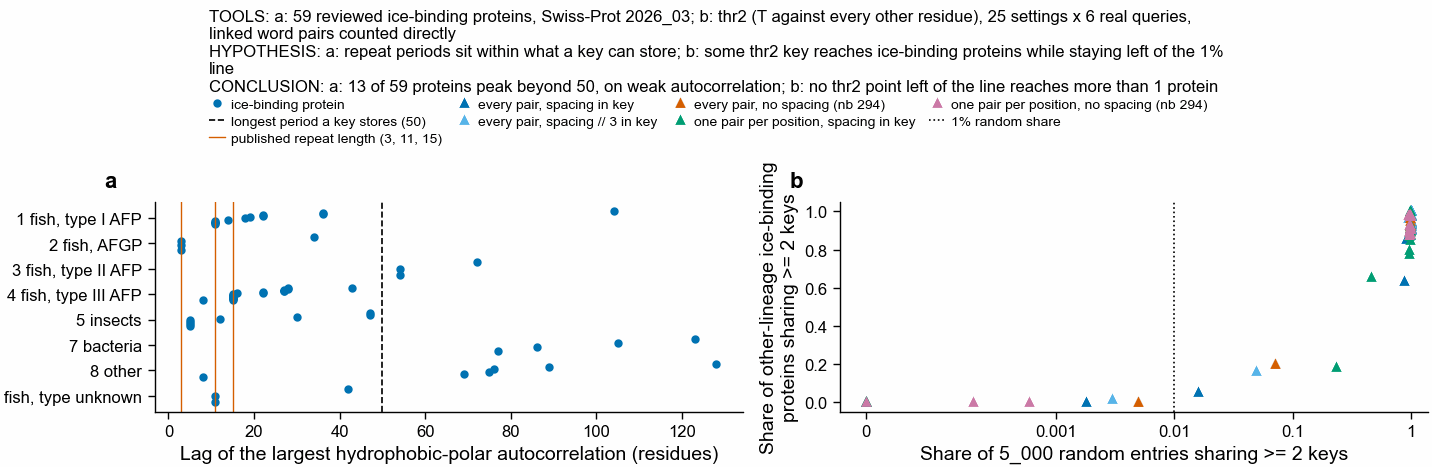

In [9]:
# (1) Could a spacing above 40 have passed? The repeat period of every truth protein,
# found as bin/prep_inputs.py finds it (largest HP autocorrelation, hp_pbotc_1st_ed2), but
# over lags up to half the protein's length instead of 30.
sys.path.insert(0, str(Path.cwd().parent / "nextflow-runs/convergence-afp/bin"))
import prep_inputs

hyd = set("ACFILMPVWY")  # hp_pbotc_1st_ed2's hydrophobic class
sprot_truth = {
    k: v
    for k, v in ceiling.read_fasta(ceiling.SPROT).items()
    if k in set(truth["Entry"])
}
rows = []
for r in truth.iter_rows(named=True):
    s = sprot_truth[r["Entry"]]
    lags = range(2, max(3, len(s) // 2) + 1)
    ac = prep_inputs.autocorrelation(prep_inputs.hp_signs(s, hyd), lags)
    rows.append(
        {
            "Entry": r["Entry"],
            "lineage": r["lineage"],
            "length": len(s),
            "period": lags[int(np.argmax(ac))],
            "autocorrelation": float(ac.max()),
        }
    )
per = pl.DataFrame(rows).sort("period", descending=True)
# The key's second word starts a + g residues after the first, so a repeat of period P is
# stored as a spacing when P - a is in the spacing range.
reachable = max(sr.PAIR_GAPS) + max(reach["word_length"])
print(
    "Repeat period of each truth protein (largest HP autocorrelation, lags 2 to length/2):"
)
print(per.head(15))
print(
    f"{(per['period'] > 40).sum()} of {per.height} truth proteins have a period above 40 "
    "residues; a key spans word + spacing, so with spacing up to 40 and words up to 10 "
    f"letters, periods up to {reachable} can be stored"
)

# (2) Targets no setting could reach by length: fewer than 2 distinct keys in every setting.
r2 = reach.filter((pl.col("kind") == "real") & (pl.col("min_shared") == 2))
short = (
    r2.group_by("lineage")
    .agg(
        targets_total=pl.col("targets_total").first(),
        most_targets_with_two_keys=pl.col("targets_with_two_keys").max(),
        fewest_targets_with_two_keys=pl.col("targets_with_two_keys").min(),
    )
    .sort("lineage")
)
print(
    "\nOther-lineage targets long enough to hold 2 distinct keys, best and worst setting:"
)
print(short)

# (3) thr2 on its own.
thr = r2.filter(pl.col("alphabet") == "thr2").select(
    "lineage",
    "word_length",
    "family",
    "targets_reached",
    "targets_total",
    "random_share",
)
best_thr = (
    thr.filter(pl.col("random_share") <= sr.RANDOM_SHARE_BAR)
    .sort("targets_reached", descending=True)
    .group_by("lineage", maintain_order=True)
    .head(1)
    .sort("lineage")
)
print("\nthr2 (T vs not T): the best setting per query with random share <= 1%:")
print(best_thr)
print(
    f"thr2 settings with random share <= 1% on all 6 queries: "
    f"{thr.group_by('word_length', 'family').agg(pl.col('random_share').max()).filter(pl.col('random_share') <= 0.01).height}"
    f" of {thr.select('word_length', 'family').unique().height}"
)

fig, (ax1, ax2) = pf.figure(pf.TWO_COLUMN_MM, 60, ncols=2)
lin_order = sorted(per["lineage"].unique())
for i, lin in enumerate(lin_order):
    v = per.filter(pl.col("lineage") == lin)["period"].to_numpy()
    ax1.plot(
        v,
        i + np.linspace(-0.25, 0.25, v.size),
        "o",
        color=pf.OKABE_ITO["blue"],
        markersize=2,
        linestyle="none",
        label="ice-binding protein" if i == 0 else None,
    )
ax1.axvline(
    reachable,
    color="black",
    linestyle="--",
    linewidth=0.6,
    label=f"longest period a key stores ({reachable})",
)
for p_, lab in [(3, "AFGP"), (11, "type I"), (15, "budworm")]:
    ax1.axvline(
        p_,
        color=pf.OKABE_ITO["vermillion"],
        linewidth=0.5,
        label="published repeat length (3, 11, 15)" if p_ == 3 else None,
    )
ax1.set_yticks(range(len(lin_order)), lin_order)
ax1.invert_yaxis()
ax1.set_xlabel("Lag of the largest hydrophobic-polar autocorrelation (residues)")
thr_all = r2.filter(pl.col("alphabet") == "thr2")
for fam, colour in FAMILY_COLOUR.items():
    f = thr_all.filter(pl.col("family") == fam)
    ax2.plot(
        np.where(f["random_share"] == 0, 2.5e-5, f["random_share"]),
        f["reach"],
        "^",
        color=colour,
        markersize=2.5,
        linestyle="none",
        label=FAMILY_LABEL[fam],
    )
ax2.axvline(
    sr.RANDOM_SHARE_BAR,
    color="black",
    linestyle=":",
    linewidth=0.6,
    label="1% random share",
)
ax2.set_xscale("log")
ax2.set_xlim(1.5e-5, 1.4)
ax2.set_xticks([2.5e-5, 1e-3, 1e-2, 1e-1, 1], ["0", "0.001", "0.01", "0.1", "1"])
ax2.minorticks_off()
ax2.set_xlabel("Share of 5_000 random entries sharing >= 2 keys")
ax2.set_ylabel("Share of other-lineage ice-binding\nproteins sharing >= 2 keys")
for ax, letter in zip((ax1, ax2), "ab"):
    pf.panel_label(ax, letter)
handles, labels = [], []
for ax in (ax1, ax2):
    h, l = ax.get_legend_handles_labels()
    handles += h
handles = [h for h in handles]
header(
    fig,
    "a: 59 reviewed ice-binding proteins, Swiss-Prot 2026_03; b: thr2 (T against every "
    "other residue), 25 settings x 6 real queries, linked word pairs counted directly",
    "a: repeat periods sit within what a key can store; b: some thr2 key reaches "
    "ice-binding proteins while staying left of the 1% line",
    f"a: {(per['period'] > reachable).sum()} of {per.height} proteins peak beyond "
    f"{reachable}, on weak autocorrelation; b: no thr2 point left of the line reaches more "
    "than 1 protein",
    handles=handles,
    ncol=4,
)
pf.save(fig, FIGURES / "298_SF5_repeat_periods_and_thr2_swissprot_2026_03")

## Summary and conclusions

**Claims the data supports.**

1. Linked word pairs do not reach ice-binding proteins of other lineages more often than
   exact k-mers do on the held-out lineages: 4 of 55 against 6 of 55 for AFGP, 0 of 40
   against 0 of 40 for fish type III, both at a random share of 1% or less (section 4).
2. Under the 1% random-share bar, no hydrophobic-polar or threonine key reaches more than
   1 ice-binding protein of another lineage from any of the six queries (F1, section 8).
   Prediction (b) held. Prediction (a), that a stored spacing would not carry across
   lineages, is consistent with the data: the spacing-in-key families reach no more than
   the families without it.
3. The few cross-lineage matches the chosen key makes are shared ancestry (the bacterial
   query and five fungal proteins of one UniProt family, a median 54 to 66% identical
   between the two words) or alanine and threonine runs, where residue-shuffled copies
   of the query reach more (section 7, SF1).
4. Notebook 294's key (hydrophobic-polar, `hp_thomas_dill2`, 6-letter words, every pair,
   no spacing) is shared 2 or more times by 95% of random Swiss-Prot entries, a mean of
   981 shared keys per random entry, so about 546_000 of Swiss-Prot's 575_748 entries for
   a query like these (SF2, `298_strobemer_chance_cost.tsv`). Used as a filter, it removes
   almost nothing.

**Claims the data does not support.**

1. That pair keys cannot carry any pattern across lineages. Only ice-binding proteins
   were tested, with 6 queries, 40 to 56 targets each, and the AFGP query is a 31-residue
   repeat that null C cannot shuffle.
2. That the chance cost in SF2 is the same for every query. It is a mean over 6 short,
   repetitive ice-binding queries (31 to 276 residues); a typical Swiss-Prot query will
   give other numbers.
3. Anything about spacings above 40 residues, or about keys of three or more words.
4. Anything about notebook 294's homology result, which this notebook does not revisit.

**The figure.** F1, `figures/298_F1_linked_pair_reach_vs_random_swissprot_2026_03.png`:
on every query the 210 linked-pair settings sit on the same curve as the exact k-mers of
notebook 295, and none sits high and left of the 1% line on a held-out query.

**Next smallest experiment.** Not another key on this truth set: the 1% bar leaves at most
one target for any hydrophobic-polar key, and what the 20-letter keys reach is ancestry.
The next one is kmerseek's own `--chain-max-shift` on the notebook 232 Pfam seed pairs,
the comparison notebook 294 left untested. It asks the homology question on data that
already exists, with a flag kmerseek already has (`src/rust/main.rs` on `main`), so it
needs no new index and no new truth set. The venom cysteine-framework test asks a pattern
question again, and its first run (PR 145, notebook 297) is already under way.

## References

Davies, P. L. "Ice-Binding Proteins: A Remarkable Diversity of Structures for Stopping and
Starting Ice Growth." *Trends in Biochemical Sciences* 39, no. 11 (2014): 548–55.
https://doi.org/10.1016/j.tibs.2014.09.005.

**Note:** checked against PubMed (PMID 25440715) on 18 Oct 2026. Cited for one sentence:
ice-binding sites are flat, extensive and relatively hydrophobic, on folds that evolved
separately.

Sahlin, K. "Effective Sequence Similarity Detection with Strobemers." *Genome Research* 31,
no. 11 (2021): 2080–94. https://doi.org/10.1101/gr.275648.121.

**Note:** the reference as resolved in notebook 294's prior-art note. Defines the linked
word pairs (strobemers) used here.